In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("telecom_customer_churn.csv")

In [3]:
df

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,Female,20,No,0,La Mesa,91941,32.759327,-116.997260,0,...,Credit Card,55.15,742.90,0.00,0,606.84,1349.74,Stayed,NaN,NaN
7039,9992-RRAMN,Male,40,Yes,0,Riverbank,95367,37.734971,-120.954271,1,...,Bank Withdrawal,85.10,1873.70,0.00,0,356.40,2230.10,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,Male,22,No,0,Elk,95432,39.108252,-123.645121,0,...,Credit Card,50.30,92.75,0.00,0,37.24,129.99,Joined,NaN,NaN
7041,9993-LHIEB,Male,21,Yes,0,Solana Beach,92075,33.001813,-117.263628,5,...,Credit Card,67.85,4627.65,0.00,0,142.04,4769.69,Stayed,NaN,NaN


## Data Exploration

In [4]:
df.head()

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.6,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.0,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.9,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.0,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.9,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability


In [5]:
df.shape

(7043, 38)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 38 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   str    
 1   Gender                             7043 non-null   str    
 2   Age                                7043 non-null   int64  
 3   Married                            7043 non-null   str    
 4   Number of Dependents               7043 non-null   int64  
 5   City                               7043 non-null   str    
 6   Zip Code                           7043 non-null   int64  
 7   Latitude                           7043 non-null   float64
 8   Longitude                          7043 non-null   float64
 9   Number of Referrals                7043 non-null   int64  
 10  Tenure in Months                   7043 non-null   int64  
 11  Offer                              3166 non-null   str    
 12  Pho

In [7]:
df.describe()

,Age,Number of Dependents,Zip Code,Latitude,Longitude,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,6361.000000,5517.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,46.509726,0.468692,93486.070567,36.197455,-119.756684,1.951867,32.386767,25.420517,26.189958,63.596131,2280.381264,1.962182,6.860713,749.099262,3034.379056
std,16.750352,0.962802,1856.767505,2.468929,2.154425,3.001199,24.542061,14.200374,19.586585,31.204743,2266.220462,7.902614,25.104978,846.660055,2865.204542
min,19.000000,0.000000,90001.000000,32.555828,-124.301372,0.000000,1.000000,1.010000,2.000000,-10.000000,18.800000,0.000000,0.000000,0.000000,21.360000
25%,32.000000,0.000000,92101.000000,33.990646,-121.788090,0.000000,9.000000,13.050000,13.000000,30.400000,400.150000,0.000000,0.000000,70.545000,605.610000
50%,46.000000,0.000000,93518.000000,36.205465,-119.595293,0.000000,29.000000,25.690000,21.000000,70.050000,1394.550000,0.000000,0.000000,401.440000,2108.640000
75%,60.000000,0.000000,95329.000000,38.161321,-117.969795,3.000000,55.000000,37.680000,30.000000,89.750000,3786.600000,0.000000,0.000000,1191.100000,4801.145000
max,80.000000,9.000000,96150.000000,41.962127,-114.192901,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000


In [8]:
df.columns

Index(['Customer ID', 'Gender', 'Age', 'Married', 'Number of Dependents',
       'City', 'Zip Code', 'Latitude', 'Longitude', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Customer Status', 'Churn Category', 'Churn Reason'],
      dtype='str')

In [9]:
df.describe(include=["str"])

,Customer ID,Gender,Married,City,Offer,Phone Service,Multiple Lines,Internet Service,Internet Type,Online Security,...,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Customer Status,Churn Category,Churn Reason
count,7043,7043,7043,7043,3166,7043,6361,7043,5517,5517,...,5517,5517,5517,5517,7043,7043,7043,7043,1869,1869
unique,7043,2,2,1106,5,2,2,2,3,2,...,2,2,2,2,3,2,3,3,5,20
top,0002-ORFBO,Male,No,Los Angeles,Offer B,Yes,No,Yes,Fiber Optic,No,...,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,Stayed,Competitor,Competitor had better devices
freq,1,3555,3641,293,824,6361,3390,5517,3035,3498,...,2810,2785,3029,4745,3610,4171,3909,4720,841,313


In [10]:
df["Customer Status"].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [11]:
df["Contract"].value_counts()


Contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64

In [12]:
df["Offer"].value_counts(dropna=False)

Offer
NaN        3877
Offer B     824
Offer E     805
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

In [13]:
df

,Customer ID,Gender,Age,Married,Number of Dependents,City,Zip Code,Latitude,Longitude,Number of Referrals,...,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Customer Status,Churn Category,Churn Reason
0,0002-ORFBO,Female,37,Yes,0,Frazier Park,93225,34.827662,-118.999073,2,...,Credit Card,65.60,593.30,0.00,0,381.51,974.81,Stayed,NaN,NaN
1,0003-MKNFE,Male,46,No,0,Glendale,91206,34.162515,-118.203869,0,...,Credit Card,-4.00,542.40,38.33,10,96.21,610.28,Stayed,NaN,NaN
2,0004-TLHLJ,Male,50,No,0,Costa Mesa,92627,33.645672,-117.922613,0,...,Bank Withdrawal,73.90,280.85,0.00,0,134.60,415.45,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Male,78,Yes,0,Martinez,94553,38.014457,-122.115432,1,...,Bank Withdrawal,98.00,1237.85,0.00,0,361.66,1599.51,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Female,75,Yes,0,Camarillo,93010,34.227846,-119.079903,3,...,Credit Card,83.90,267.40,0.00,0,22.14,289.54,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,Female,20,No,0,La Mesa,91941,32.759327,-116.997260,0,...,Credit Card,55.15,742.90,0.00,0,606.84,1349.74,Stayed,NaN,NaN
7039,9992-RRAMN,Male,40,Yes,0,Riverbank,95367,37.734971,-120.954271,1,...,Bank Withdrawal,85.10,1873.70,0.00,0,356.40,2230.10,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,Male,22,No,0,Elk,95432,39.108252,-123.645121,0,...,Credit Card,50.30,92.75,0.00,0,37.24,129.99,Joined,NaN,NaN
7041,9993-LHIEB,Male,21,Yes,0,Solana Beach,92075,33.001813,-117.263628,5,...,Credit Card,67.85,4627.65,0.00,0,142.04,4769.69,Stayed,NaN,NaN


## Data Cleaning and Validation

In [14]:
required_columns = [
    "Customer ID",
    "Tenure in Months",
    "Offer",
    "Phone Service",
    "Multiple Lines",
    "Internet Service",
    "Internet Type",
    "Premium Tech Support",
    "Contract",
    "Customer Status",
    "Churn Category",
    "Churn Reason"
]

In [15]:
df = df[required_columns]

In [16]:
df.shape

(7043, 12)

In [17]:
new_columns = [
    "customer_id",
    "tenure_in_months",
    "offer",
    "phone_service",
    "multiple_lines",
    "internet_service",
    "internet_type",
    "premium_tech_support",
    "contract",
    "customer_status",
    "churn_category",
    "churn_reason"
]

In [18]:
df.columns = new_columns

In [19]:
df.columns

Index(['customer_id', 'tenure_in_months', 'offer', 'phone_service',
       'multiple_lines', 'internet_service', 'internet_type',
       'premium_tech_support', 'contract', 'customer_status', 'churn_category',
       'churn_reason'],
      dtype='str')

In [20]:
df

,customer_id,tenure_in_months,offer,phone_service,multiple_lines,internet_service,internet_type,premium_tech_support,contract,customer_status,churn_category,churn_reason
0,0002-ORFBO,9,NaN,Yes,No,Yes,Cable,Yes,One Year,Stayed,NaN,NaN
1,0003-MKNFE,9,NaN,Yes,Yes,Yes,Cable,No,Month-to-Month,Stayed,NaN,NaN
2,0004-TLHLJ,4,Offer E,Yes,No,Yes,Fiber Optic,No,Month-to-Month,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,13,Offer D,Yes,No,Yes,Fiber Optic,No,Month-to-Month,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,3,NaN,Yes,No,Yes,Fiber Optic,Yes,Month-to-Month,Churned,Dissatisfaction,Network reliability
...,...,...,...,...,...,...,...,...,...,...,...,...
7038,9987-LUTYD,13,Offer D,Yes,No,Yes,DSL,Yes,One Year,Stayed,NaN,NaN
7039,9992-RRAMN,22,Offer D,Yes,Yes,Yes,Fiber Optic,No,Month-to-Month,Churned,Dissatisfaction,Product dissatisfaction
7040,9992-UJOEL,2,Offer E,Yes,No,Yes,DSL,No,Month-to-Month,Joined,NaN,NaN
7041,9993-LHIEB,67,Offer A,Yes,No,Yes,Cable,Yes,Two Year,Stayed,NaN,NaN


In [21]:
df["offer"] = df["offer"].fillna("No Offer")

In [22]:
df["offer"].value_counts()

offer
No Offer    3877
Offer B      824
Offer E      805
Offer D      602
Offer A      520
Offer C      415
Name: count, dtype: int64

In [23]:
df['internet_type'].isnull().sum()

np.int64(1526)

In [24]:
missing_internet = df[df["internet_type"].isna()]

In [25]:
missing_internet["internet_service"].value_counts()

internet_service
No    1526
Name: count, dtype: int64

In [26]:
df["internet_type"] = df["internet_type"].fillna("No Internet Service")

In [27]:
df["internet_type"].value_counts()

internet_type
Fiber Optic            3035
DSL                    1652
No Internet Service    1526
Cable                   830
Name: count, dtype: int64

In [28]:
missing_lines = df[df["multiple_lines"].isna()]

In [29]:
missing_lines["phone_service"].value_counts(dropna=False)

phone_service
No    682
Name: count, dtype: int64

In [30]:
df["multiple_lines"] = df["multiple_lines"].fillna("No Phone Service")

In [31]:
df["multiple_lines"].value_counts()

multiple_lines
No                  3390
Yes                 2971
No Phone Service     682
Name: count, dtype: int64

In [32]:
missing_support = df[df["premium_tech_support"].isna()]

In [33]:
missing_support["internet_service"].value_counts()

internet_service
No    1526
Name: count, dtype: int64

In [34]:
df["premium_tech_support"] = df["premium_tech_support"].fillna("No Internet Service")

In [35]:
df["premium_tech_support"].value_counts()

premium_tech_support
No                     3473
Yes                    2044
No Internet Service    1526
Name: count, dtype: int64

In [36]:
missing_reasons = df[df["churn_reason"].isna()]

In [37]:
missing_reasons["customer_status"].value_counts()

customer_status
Stayed    4720
Joined     454
Name: count, dtype: int64

In [38]:
df["churn_reason"] = df["churn_reason"].fillna("Not Applicable")

In [39]:
df["churn_reason"].isna().sum()

np.int64(0)

In [40]:
missing_categories = df[df["churn_category"].isna()]

missing_categories["customer_status"].value_counts(dropna=False)

customer_status
Stayed    4720
Joined     454
Name: count, dtype: int64

In [41]:
df["churn_category"] = df["churn_category"].fillna("Not Applicable")

In [42]:
df.isna().sum()

customer_id             0
tenure_in_months        0
offer                   0
phone_service           0
multiple_lines          0
internet_service        0
internet_type           0
premium_tech_support    0
contract                0
customer_status         0
churn_category          0
churn_reason            0
dtype: int64

In [43]:
text_columns = [
    "customer_id",
    "offer",
    "phone_service",
    "multiple_lines",
    "internet_service",
    "internet_type",
    "premium_tech_support",
    "contract",
    "customer_status",
    "churn_category",
    "churn_reason"
]


In [44]:
for column in text_columns:
    df[column] = df[column].str.strip()

In [45]:
df.duplicated().sum()

np.int64(0)

In [46]:
df["customer_id"].duplicated().sum()

np.int64(0)

In [47]:
df["tenure_in_months"].min()

np.int64(1)

In [48]:
df["tenure_in_months"].max()

np.int64(72)

In [49]:
df.dtypes

customer_id               str
tenure_in_months        int64
offer                     str
phone_service             str
multiple_lines            str
internet_service          str
internet_type             str
premium_tech_support      str
contract                  str
customer_status           str
churn_category            str
churn_reason              str
dtype: object

## Data Transformation

In [50]:
df["churn_flag"] = df["customer_status"].map({
    "Churned": 1,
    "Stayed": 0,
    "Joined": 0
})

In [51]:
df["churn_flag"].value_counts()

churn_flag
0    5174
1    1869
Name: count, dtype: int64

In [52]:
df["tenure_group"] = pd.cut(
    df["tenure_in_months"],
    bins=[0, 12, 24, 48, 72],
    labels=["1-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

In [53]:
df["tenure_group"].value_counts(sort=False)

tenure_group
1-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64

## Data Analysis

In [54]:
churned_count = df["churn_flag"].sum()

total_customers = len(df)

churn_rate = (churned_count / total_customers) * 100

In [55]:
churn_rate = round(churn_rate, 2)

In [56]:
churn_rate

np.float64(26.54)

In [57]:
df.head(7)

,customer_id,tenure_in_months,offer,phone_service,multiple_lines,internet_service,internet_type,premium_tech_support,contract,customer_status,churn_category,churn_reason,churn_flag,tenure_group
0,0002-ORFBO,9,No Offer,Yes,No,Yes,Cable,Yes,One Year,Stayed,Not Applicable,Not Applicable,0,1-12 Months
1,0003-MKNFE,9,No Offer,Yes,Yes,Yes,Cable,No,Month-to-Month,Stayed,Not Applicable,Not Applicable,0,1-12 Months
2,0004-TLHLJ,4,Offer E,Yes,No,Yes,Fiber Optic,No,Month-to-Month,Churned,Competitor,Competitor had better devices,1,1-12 Months
3,0011-IGKFF,13,Offer D,Yes,No,Yes,Fiber Optic,No,Month-to-Month,Churned,Dissatisfaction,Product dissatisfaction,1,13-24 Months
4,0013-EXCHZ,3,No Offer,Yes,No,Yes,Fiber Optic,Yes,Month-to-Month,Churned,Dissatisfaction,Network reliability,1,1-12 Months
5,0013-MHZWF,9,Offer E,Yes,No,Yes,Cable,Yes,Month-to-Month,Stayed,Not Applicable,Not Applicable,0,1-12 Months
6,0013-SMEOE,71,Offer A,Yes,No,Yes,Fiber Optic,Yes,Two Year,Stayed,Not Applicable,Not Applicable,0,49-72 Months


In [58]:
churned_customers = df[df["customer_status"] == "Churned"]

In [59]:
churn_categories = churned_customers["churn_category"].value_counts()

In [60]:
churn_categories

churn_category
Competitor         841
Dissatisfaction    321
Attitude           314
Price              211
Other              182
Name: count, dtype: int64

In [61]:
contract_churn = df.groupby("contract")["churn_flag"].mean()

In [62]:
contract_churn

contract
Month-to-Month    0.458449
One Year          0.107097
Two Year          0.025491
Name: churn_flag, dtype: float64

In [63]:
contract_churn = contract_churn * 100

In [64]:
contract_churn = contract_churn.round(2)

In [65]:
contract_churn

contract
Month-to-Month    45.84
One Year          10.71
Two Year           2.55
Name: churn_flag, dtype: float64

In [66]:
tenure_churn = df.groupby("tenure_group")["churn_flag"].mean()

In [67]:
tenure_churn = tenure_churn * 100

In [68]:
tenure_churn = tenure_churn.round(2)

In [69]:
tenure_churn

tenure_group
1-12 Months     47.44
13-24 Months    28.71
25-48 Months    20.39
49-72 Months     9.51
Name: churn_flag, dtype: float64

In [70]:
contract_customer_counts = df["contract"].value_counts()

In [71]:
contract_customer_counts

contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64

In [72]:
top_churn_reasons = churned_customers["churn_reason"].value_counts().head(5)

top_churn_reasons

churn_reason
Competitor had better devices    313
Competitor made better offer     311
Attitude of support person       220
Don't know                       130
Competitor offered more data     117
Name: count, dtype: int64

## Data Visualization

In [73]:
customer_status_counts = df["customer_status"].value_counts()

In [74]:
customer_status_counts

customer_status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

In [75]:
lab = customer_status_counts.index

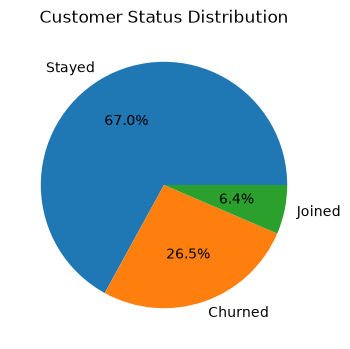

In [76]:
plt.figure(figsize=(4,4))
plt.pie(customer_status_counts, labels=["Stayed","Churned","Joined"], autopct="%1.1f%%")
plt.title("Customer Status Distribution")
plt.show()

#### Observations

1. About 67% of customers are staying in thid company.
2. Around 26% of customers have left the company.
3. 6.4% of customers have recently joined the company


In [77]:
ci = churn_categories.index

In [78]:
cv = churn_categories.values

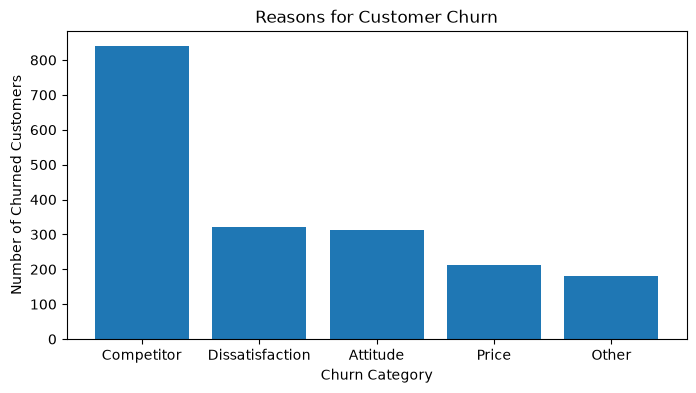

In [79]:
plt.figure(figsize=(8,4))
plt.bar(ci, cv)
plt.title("Reasons for Customer Churn")
plt.xlabel("Churn Category")
plt.ylabel("Number of Churned Customers")
plt.show()

#### Observations :

The main reason of customer churning is Competitor which shows that customer gets attracted to other company by their policy, offers, etc.

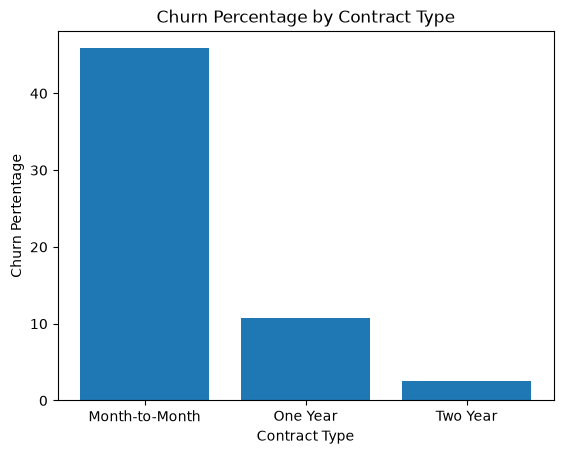

In [80]:
plt.bar(contract_churn.index, contract_churn.values)
plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Pertentage")
plt.show()

#### Observations :
From this chart, it has been found that Month-To-Month contract type were having the most churn customers.

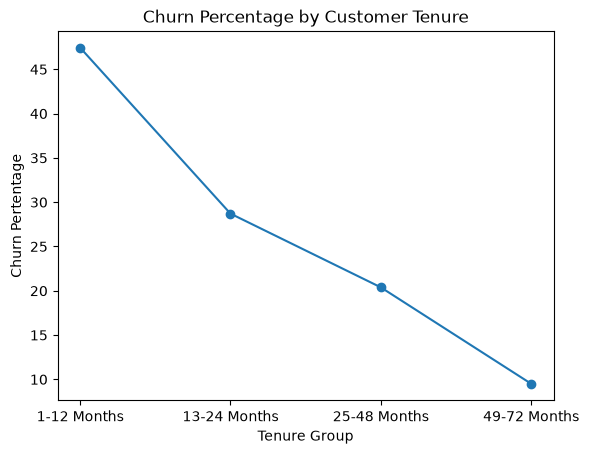

In [81]:
plt.plot(tenure_churn.index, tenure_churn.values, marker="o")
plt.title("Churn Percentage by Customer Tenure")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Pertentage")
plt.show()

#### Observations :

From this chart it has been found that the more time customers are using the service the less they are churned. And the less time customers are using the service the more that are getting churned.

## Business Recommendation

Around 67% of customers are staying with this company but yet around a quarter of the customers are leaving this company. So the company should foucs to reduce the customer churning and also to regain new customers.

most of the customers are leaving this service because they are findinf better service in other company, so the company should focus on its offers, policies, services etc to reduce customer churning.

The company should focus on their Month-To-Month contract type as because in this contract type most of the customers are leaving. So the business should recreate or reanalyze this contract type.

The most recently joined (Within 1 year) customers are mostly leaving this company. With time the churning reduces. So the company should focus on the new joined customers.